# 03 Recommenders

This notebook contains everything after the EDA. Part 1 sets up the evaluation that every recommender uses. The following parts build and evaluate the recommenders, and the last parts compare them and estimate the business value.

| Part | Content |
|---|---|
| 1 | Evaluation setup |
| 2 | Non-personalized recommenders (random, popular, demographic) |
| 3 | Collaborative filtering |
| 4 | Content-based |
| 5 | Hybrid |
| 6 | Context-aware |
| 7 | Bandits |
| 8 | Final comparison and business value |

The data is the cleaned sample from `01_preprocessing.ipynb`, described in `02_eda.ipynb`.

# Part 1. Evaluation setup

Every recommender is compared on the same split, the same definition of a relevant anime and the same metric functions. This part makes those choices once and checks them.

## 1.1 Libraries

In [1]:
%pip install -q pandas pyarrow scikit-surprise rexmex "seaborn>=0.13" "plotly>=5" funcsigs six
%pip install -q --no-deps recmetrics

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


**Why recmetrics is installed without its dependencies.** recmetrics 0.1.5 requires pandas below 2.0 and seaborn below 0.12. The course notebooks work around this by switching Colab to Python 3.11 and installing old versions of pandas, numpy and seaborn [4, p. 1]. That Colab runtime (2025.07) is no longer offered, and current runtimes use Python 3.12 [10], for which pandas 1.5 is not available. Installing recmetrics with `--no-deps` on top of current pandas, seaborn and plotly avoids the conflict. The metric functions themselves only use numpy, pandas, scipy and scikit-learn, which work in current versions, and they return the same values as the examples in the S08 notebook.

In [2]:
from collections import defaultdict
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import recmetrics
import sklearn.metrics as metrics
from rexmex import ClassificationMetricSet, ScoreCard
from rexmex.metrics.ranking import mean_average_precision_at_k, mean_average_recall_at_k
from sklearn.model_selection import TimeSeriesSplit
from surprise import AlgoBase, Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## 1.2 Data, explicit and implicit feedback

In [3]:
interactions_df = pd.read_parquet("../data/processed/interactions.parquet")
users_df = pd.read_parquet("../data/processed/users.parquet")
anime_df = pd.read_parquet("../data/processed/anime.parquet")

# Some titles contain HTML codes such as &#039;
anime_df["title"] = anime_df["title"].map(html.unescape)

# Explicit feedback: rows with a score
ratings_df = interactions_df[interactions_df["score"] > 0].reset_index(drop=True)
print("Explicit ratings:", len(ratings_df))

status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
print()
print("Average score per status")
print(ratings_df.groupby(ratings_df["status"].map(status_names))["score"].agg(["mean", "count"]).round(2))

Explicit ratings: 977062

Average score per status
           mean   count
status                 
completed  7.66  893971
dropped    4.93   33828
on hold    7.20   22644
watching   7.98   26619


In [4]:
# Explicit relevance: a score of 8 or more (see 02_eda)
relevant_score = 8

# Implicit feedback: 1 for completed or watching, 0 for on hold, dropped and plan to watch
interactions_df["implicit"] = interactions_df["status"].isin([1, 2]).astype(int)
print("Share of interactions labelled 1:", round(interactions_df["implicit"].mean(), 3))

Share of interactions labelled 1: 0.686


**Implicit feedback.** An interaction counts as positive (1) when the anime is completed or being watched. On hold, dropped and plan to watch count as 0.

The reason is that implicit feedback should mark consumption the user was happy with, not every action. A purchase or a full stream is a positive implicit rating, while returning a product is a negative one [2, p. 83]. Turning events into 0 and 1 is a design choice that has to be justified for each dataset [3, p. 16]. The scores in this data support the split. Users who rated an anime they are still watching give it 7.98 on average and completed anime get 7.66. Dropped anime get only 4.93, so dropping is clearly a negative signal. On hold anime get 7.20, below both positive statuses and below the relevance threshold of 8 from 02_eda.

A counterargument is that plan to watch also shows interest, since the user chose to add the anime. But the user has not watched it, so it cannot tell whether they liked it. It is closer to a product view than a purchase, which is labelled 0 in the course example [3, p. 16]. On hold is the less clear case, since its average is still positive. It is labelled 0 because the user stopped watching, and only 2.3% of the rated interactions have this status, so the choice has little effect on the results. With this rule 68.6% of all interactions are positive.

## 1.3 Train and test splits
### Random split

In [5]:
reader = Reader(rating_scale=(1, 10))
data = Dataset.load_from_df(ratings_df[["user_id", "anime_id", "score"]], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=my_seed)

train_items = {trainset.to_raw_iid(i) for i in trainset.all_items()}
test_df = pd.DataFrame(testset, columns=["user_id", "anime_id", "score"])

print("Train ratings:", trainset.n_ratings, " test ratings:", len(testset))
print("Users in the test set:", test_df["user_id"].nunique(), "of", trainset.n_users)
print("Test anime that are not in the train set:", len(set(test_df["anime_id"]) - train_items))
print()
print("Test ratings per user")
print(test_df.groupby("user_id").size().describe().round(1))

Train ratings: 781649  test ratings: 195413
Users in the test set: 4982 of 5000
Test anime that are not in the train set: 57

Test ratings per user
count    4982.0
mean       39.2
std        46.2
min         1.0
25%        11.0
50%        25.0
75%        50.0
max       592.0
dtype: float64


### Split per user

In [6]:
def split_per_user(ratings_df, test_size=0.2):
    # Each user puts test_size of their own ratings in the test set
    test_df = ratings_df.groupby("user_id", group_keys=False).sample(frac=test_size, random_state=my_seed)
    train_df = ratings_df.drop(test_df.index)
    trainset = Dataset.load_from_df(train_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    testset = list(test_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    return trainset, testset

trainset_per_user, testset_per_user = split_per_user(ratings_df)
test_per_user_df = pd.DataFrame(testset_per_user, columns=["user_id", "anime_id", "score"])

print("Users in the test set:", test_per_user_df["user_id"].nunique())
print("Fewest test ratings for a user:", test_per_user_df.groupby("user_id").size().min())

Users in the test set: 5000
Fewest test ratings for a user: 2


### Cross-validation through time (CVTT)

In [7]:
# Ordering by time and resetting the index is needed, since TimeSeriesSplit is based on the index
ratings_by_time_df = ratings_df.sort_values("last_updated").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    rows.append({
        "fold": fold,
        "train until": train_fold["last_updated"].max().date(),
        "test until": test_fold["last_updated"].max().date(),
        "test users with no train history %": round(100 * (1 - test_fold["user_id"].isin(train_fold["user_id"]).mean()), 1),
        "test ratings on anime not in train %": round(100 * (1 - test_fold["anime_id"].isin(train_fold["anime_id"]).mean()), 1),
        "mean test score": round(test_fold["score"].mean(), 2),
    })
pd.DataFrame(rows)

,fold,train until,test until,test users with no train history %,test ratings on anime not in train %,mean test score
0,1,2010-05-06,2012-06-16,56.2,28.1,7.67
1,2,2012-06-16,2014-01-15,47.7,30.3,7.62
2,3,2014-01-15,2015-06-30,34.9,28.5,7.53
3,4,2015-06-30,2016-10-28,31.3,31.1,7.50
4,5,2016-10-28,2018-05-22,25.0,26.7,7.39


**Which split to use.** The random 80/20 split is the main split for comparing models. The per-user split and CVTT are used as checks on the final candidates.

The random split is the standard method in the course [5, p. 4], and it represents almost everything in the test set. 4,982 of the 5,000 users have test ratings, the median user has 25, and only 57 test anime are missing from training. The same split is used by every notebook through the split in 1.3, so all models are tested on exactly the same ratings.

The per-user split puts 20% of every user's ratings in the test set. It solves the problem that a random split can leave a user with no test data by chance [5, p. 28]. Here it only adds the 18 missing users, and every user gets at least 2 test ratings. Because the gain is small, it is used as a robustness check rather than the main split. It is also one of the advanced evaluation options in the course [9].

CVTT trains on the past and tests on later ratings, which is how the system would work in production [5, p. 27]. The table shows why it cannot be the main split for every model. In the first fold 56.2% of the test users have no history in the training data, and even in the last fold 25.0% have none. Between 26.7% and 31.1% of test ratings are on anime that did not exist in the training period. A collaborative filtering model cannot score these users or anime, so CVTT mixes the cold start problem into every comparison. It is still essential for two parts of the project. The average test score falls from 7.67 to 7.39 across the folds, the same downward drift found in 02_eda, so a random split lets models learn from the future. CVTT therefore measures how the final system and the context-aware models perform on genuinely new data.

The main counterargument to the random split is exactly this leakage of future ratings into training, which makes all results slightly optimistic. The leakage affects every model in the same way, so it does not change which model ranks first. The final candidates are re-tested with CVTT to confirm the choice holds on future data.

## 1.4 Metric functions

`get_top_n` and `ndcg_multiple_users` are the functions from the S10 notebook. `test_ranking_metrics` adds MAP and MAR from rexmex (S08). `top_n_unseen` ranks every anime a user has not rated, which is what a homepage would show.

In [8]:
def get_top_n(predictions, n=10, solve_ties=False):
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))
    for uid, user_ratings in top_n.items():
        if solve_ties:
            user_ratings.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n


def ndcg_multiple_users(relevant_items_all_users, predictions_ranking_all_users, k=5):
    ndcg_list = []
    for i in range(len(relevant_items_all_users)):
        # Skip users with only 1 item in the test data, as no NDCG can be computed
        if len(relevant_items_all_users[i]) > 1:
            ndcg = metrics.ndcg_score([relevant_items_all_users[i]], [predictions_ranking_all_users[i]], k=k)
            ndcg_list.append(ndcg)
    return np.mean(ndcg_list)

In [9]:
def accuracy_metrics(predictions):
    return {"RMSE": accuracy.rmse(predictions, verbose=False),
            "MAE": accuracy.mae(predictions, verbose=False)}


def test_ranking_metrics(predictions, k=10, min_test_items=1):
    # Rank each user's test anime by the predicted score
    df = pd.DataFrame(predictions)
    by_user = df.groupby("uid")[["iid", "r_ui", "est"]].agg(list)
    by_user = by_user[by_user["iid"].str.len() >= min_test_items]

    # MAP and MAR need the relevant anime and the ranking as lists of ids
    relevant_items, rankings = [], []
    for iids, scores, ests in zip(by_user["iid"], by_user["r_ui"], by_user["est"]):
        relevant = [i for i, s in zip(iids, scores) if s >= relevant_score]
        if relevant:
            relevant_items.append(relevant)
            rankings.append([i for _, i in sorted(zip(ests, iids), reverse=True)])

    return {f"NDCG@{k}": ndcg_multiple_users(by_user["r_ui"].tolist(), by_user["est"].tolist(), k=k),
            f"MAP@{k}": mean_average_precision_at_k(relevant_items, rankings, k=k),
            f"MAR@{k}": mean_average_recall_at_k(relevant_items, rankings, k=k),
            "users": len(by_user)}

In [10]:
def eval_users(trainset, n=1000):
    # The same random users for every model
    raw_users = sorted(trainset.to_raw_uid(u) for u in trainset.all_users())
    rng = np.random.default_rng(my_seed)
    return list(rng.choice(raw_users, size=n, replace=False))


def top_n_unseen(algo, trainset, users, n=10, solve_ties=False):
    # Same result as build_anti_testset() + test() + get_top_n(), but one user at a time to save memory
    rng = np.random.default_rng(my_seed)
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    top_n = {}
    for uid in users:
        seen = {trainset.to_raw_iid(i) for i, _ in trainset.ur[trainset.to_inner_uid(uid)]}
        scores = [(iid, algo.predict(uid, iid).est) for iid in all_items if iid not in seen]
        if solve_ties:
            scores.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            rng.shuffle(scores)  # ties are broken at random
            scores.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for iid, _ in scores[:n]]
    return top_n


def homepage_hits(top_n, testset):
    # Relevant test anime among the 10 anime shown to each user
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    hits = [len(set(items) & relevant[uid]) for uid, items in top_n.items()]
    return {"hits out of 10": np.mean(hits),
            "users with at least 1 hit %": 100 * np.mean([h > 0 for h in hits])}


genres_df = anime_df.set_index("anime_id")["genre"].fillna("").str.get_dummies(sep=", ")

def beyond_accuracy_metrics(top_n, trainset):
    # Use a model fitted on build_full_trainset(), never on a train and test split
    catalog = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    lists = list(top_n.values())
    return {"coverage %": recmetrics.prediction_coverage(lists, catalog),
            "personalization": recmetrics.personalization(lists),
            "intra-list similarity": recmetrics.intra_list_similarity(lists, genres_df)}

## 1.5 Check of the setup

The setup is checked with three recommenders whose behaviour is known in advance. The random and popular classes are written as in the S10 notebook. The popular one stores the averages in a dictionary instead of a dataframe, which gives the same predictions much faster. Part 2 evaluates and interprets these baselines in full. Here they only check that the evaluation code behaves as expected.

In [11]:
class MyRandomAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return np.random.normal(loc=self.train_mean, scale=self.train_std)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = [r for (_, _, r) in self.trainset.all_ratings()]
        self.train_mean = np.mean(ratings)
        self.train_std = np.std(ratings)
        return self


class MyPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.mean_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        self.mean_rating_per_item = ratings.groupby("item")["rating"].mean().to_dict()
        return self


check_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "SVD (default)": SVD(random_state=my_seed),
}

### Accuracy and ranking of the test items

In [12]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {"model": name}
    row.update(accuracy_metrics(predictions))
    row.update(test_ranking_metrics(predictions))
    row["NDCG@10 (users with 20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (users with 20+ test items)
model,,,,,,,
Random,2.346,1.859,0.860,0.556,0.387,4982,0.812
Popular,1.552,1.184,0.932,0.784,0.509,4982,0.912
SVD (default),1.247,0.930,0.938,0.800,0.520,4982,0.919


**Ranking metrics on the test items overstate weak models.** The ordering is as expected. SVD is best on every metric, popular comes second and random is last [5, pp. 8-9]. But random still reaches an NDCG@10 of 0.860 and a MAP@10 of 0.556.

Two effects explain this. First, these metrics only rank each user's own test ratings. Many users have few test ratings, and a short list leaves little room for a bad ranking [7, pp. 14-15]. Second, 55.7% of all ratings are 8 or more (02_eda), so even a random order puts relevant anime near the top. The difference between an 8 and a 9 also barely moves NDCG [7, p. 17].

The evidence is in the last column. For users with at least 20 test ratings, the NDCG of random drops from 0.860 to 0.812, while SVD only drops from 0.938 to 0.919. The gap between random and SVD grows from 0.078 to 0.107. Longer test lists make it possible to rank badly, so the metric separates the models better. For this reason every notebook reports NDCG for users with 20 or more test items next to the overall value.

The RMSE results follow the same order. Random has an RMSE of 2.35 because it draws scores around the mean with the full spread of the data. Popular reduces it to 1.55 and SVD to 1.25. One could argue RMSE alone is enough to rank models, but RMSE measures every predicted score, while the homepage only shows the top 10. A model can predict well on average and still rank the top poorly, which is why ranking metrics are needed as well [2, p. 227].

### Top 10 over the whole catalog

In [13]:
users = eval_users(trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(homepage_hits(top_n, testset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,hits out of 10,users with at least 1 hit %
model,,
Random,0.028,2.7
Popular,0.000,0.0
SVD (default),0.652,39.6


**The homepage metric is the closest to the business question.** It ranks every anime the user has not rated, takes the top 10 and counts how many are relevant anime from the user's test set. SVD finds 0.652 relevant anime per 10 shown, against 0.028 for random. That is about 23 times more, and 39.6% of users get at least one hit against 2.7% with random.

Popular gets 0 hits. Its top 10 consists of anime with an average of 10 from a single rating. Twelve anime in the training data have exactly one rating of 10, so the plain average puts them above every well-known title. Nobody else has rated them, so they never match a test rating. This is a weakness of the plain average, and Part 2 fixes it with a Bayesian average.

The absolute numbers are low on purpose and should not be read as the real hit rate. The metric only counts an anime as a hit if the user rated it in the test set. An anime the user would have loved but never rated counts as a miss. Offline evaluation is therefore biased towards what users already found by themselves [6, pp. 96-97]. The same bias applies to every model, so the ratio between models is meaningful even though the level is too low. This also explains why random gets 0.028 here and 0.16 in 02_eda. The EDA counted all of a user's relevant anime, while here only the 20% in the test set can count.

The same 1,000 users are used for every model. Ranking all unrated anime for 1,000 users means about 6 million predictions per model, which is the size of the anti-testset of the course example (610 users and 9,724 movies) [5, p. 2]. All 5,000 users would take five times longer for the memory-based models in Part 3.

In [14]:
full_trainset = data.build_full_trainset()
full_users = eval_users(full_trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(beyond_accuracy_metrics(top_n, full_trainset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,coverage %,personalization,intra-list similarity
model,,,
Random,80.52,0.998,0.180
Popular,0.31,0.077,0.141
SVD (default),14.58,0.918,0.269


**The beyond-accuracy metrics behave as theory predicts, which confirms the setup is correct.** Random reaches 80.5% coverage, popular 0.3% and SVD 14.6%. Personalization is 0.998 for random, 0.077 for popular and 0.918 for SVD. This is the expected order. Random should have the highest coverage and personalization, popular the lowest, and collaborative filtering in between [5, p. 20; 8].

These metrics are computed on `build_full_trainset()`, with every anime the user has not rated as candidates. They do not need a test set because they describe what is shown, not whether it is liked. A train and test split would only use the small fraction of known ratings and make all recommenders look alike on coverage [8]. Random cannot reach 100% here because 1,000 users with 10 anime each fill 10,000 slots out of 5,980 anime, and random draws repeat. The expected share of distinct anime is about 81%, which matches the result.

The setup needed one fix to get there. Surprise clips predictions to the rating scale, so the 7.8% of random predictions above 10 all become exactly 10. Each user then has hundreds of anime tied at 10, and a stable sort keeps them in the same catalogue order for everyone. In a first run this gave random a coverage of only 5.3%. Ties are now broken at random, which is the intended default [5, p. 17]. Popular uses `solve_ties=True` instead, so it gives every user the same list [5, p. 18]. Its personalization is still not exactly 0, because anime a user already rated are removed from their list.

Intra-list similarity measures how alike the genres in each list are, so lower means more diverse [4, p. 26]. SVD has the highest value (0.269), which means its lists are the most similar in genre. This fits collaborative filtering, which recommends anime close to what the user already likes. It is a trade-off to watch, not a flaw on its own. Very high diversity, like that of random, is not good either [4, pp. 25-26]. Coverage and personalization also depend on the number of users and the catalogue size [4, pp. 23, 25]. That is why every model is evaluated on the same 1,000 users.

## 1.6 Rules for every part

1. Every part uses `trainset` and `testset` from the random split in 1.3. The per-user split and CVTT are only used as checks.
2. Explicit relevance is `relevant_score = 8`. Implicit relevance is the `implicit` column from 1.2.
3. Report RMSE and MAE, NDCG, MAP and MAR at 10 with `test_ranking_metrics()`, plus NDCG for users with 20 or more test items.
4. Report homepage hits with `top_n_unseen()` on `trainset` and `homepage_hits()`, for the 1,000 users from `eval_users()`.
5. Report coverage, personalization and intra-list similarity with `top_n_unseen()` on `full_trainset` and `beyond_accuracy_metrics()`. Never use a train and test split for these.
6. Set `random_state=my_seed` in every model and split.
7. Compare every model with random, the company's current strategy.

# Part 6. Context-aware

Rishi's draft. Part 1 above is copied from 03_recommenders so this notebook runs on its own.

The only context we have is time. `last_updated` tells us when the user last changed the anime on their list. We don't have device, location at the moment of watching or the hour in the user's time zone (02_eda shows why the hour is not useful). Country is a user attribute and not a context, and 02_eda already showed that regions like almost the same anime.

So the question for this part is: **does it matter *when* a user visits the homepage, and can we use that to show better anime?**

## Context features from last_updated

In [15]:
seasons = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

ratings_df["year"] = ratings_df["last_updated"].dt.year
ratings_df["season"] = ratings_df["last_updated"].dt.month.map(seasons)
ratings_df["weekday"] = ratings_df["last_updated"].dt.day_name()
ratings_df["weekend"] = ratings_df["last_updated"].dt.dayofweek >= 5

# Time of every rating, to look it up later for the train and test rows
rating_time = ratings_df.set_index(["user_id", "anime_id"])["last_updated"]
print("One time per user and anime:", rating_time.index.is_unique)
print("Data ends on:", ratings_df["last_updated"].max())
ratings_df[["year", "season", "weekday", "weekend"]].head()

One time per user and anime: True
Data ends on: 2018-05-22 01:51:53


,year,season,weekday,weekend
0,2007,autumn,Tuesday,False
1,2007,autumn,Tuesday,False
2,2007,autumn,Tuesday,False
3,2007,autumn,Tuesday,False
4,2007,autumn,Tuesday,False


We keep year, season and weekday (plus a weekend flag). Hour is left out as decided in 02_eda.

One caveat: `last_updated` is the last time the user edited that entry, not the exact moment they watched it. Someone who changes an old score in 2017 moves that rating to 2017. So the time context is a bit noisy, and we should keep that in mind when reading the results.

## Which context variables matter?

First we check if the score changes with the context. We use Welch t-tests (we don't assume equal variances). With almost a million ratings almost any difference will be significant, so we also look at the effect size (Cohen's d). Rough rule: d below 0.2 is a small effect.

In [16]:
from scipy import stats


def cohens_d(x, y):
    return (x.mean() - y.mean()) / np.sqrt((x.var() + y.var()) / 2)


def compare(name, mask):
    x, y = ratings_df.loc[mask, "score"], ratings_df.loc[~mask, "score"]
    t, p = stats.ttest_ind(x, y, equal_var=False)
    return {"context": name, "mean in group": x.mean(), "mean rest": y.mean(), "t": t, "p-value": p, "Cohen's d": cohens_d(x, y)}


tests = [compare("weekend", ratings_df["weekend"])]
for s in ["winter", "spring", "summer", "autumn"]:
    tests.append(compare(s, ratings_df["season"] == s))
tests.append(compare("2017 or later", ratings_df["year"] >= 2017))

pd.DataFrame(tests).set_index("context").round(4)

,mean in group,mean rest,t,p-value,Cohen's d
context,,,,,
weekend,7.5808,7.5573,6.2716,0.0000,0.0137
winter,7.5267,7.5778,-12.8753,0.0000,-0.0298
spring,7.5889,7.5560,8.3626,0.0000,0.0192
summer,7.5858,7.5577,6.9792,0.0000,0.0164
autumn,7.5568,7.5670,-2.4893,0.0128,-0.0060
2017 or later,7.3793,7.5966,-43.0696,0.0000,-0.1249


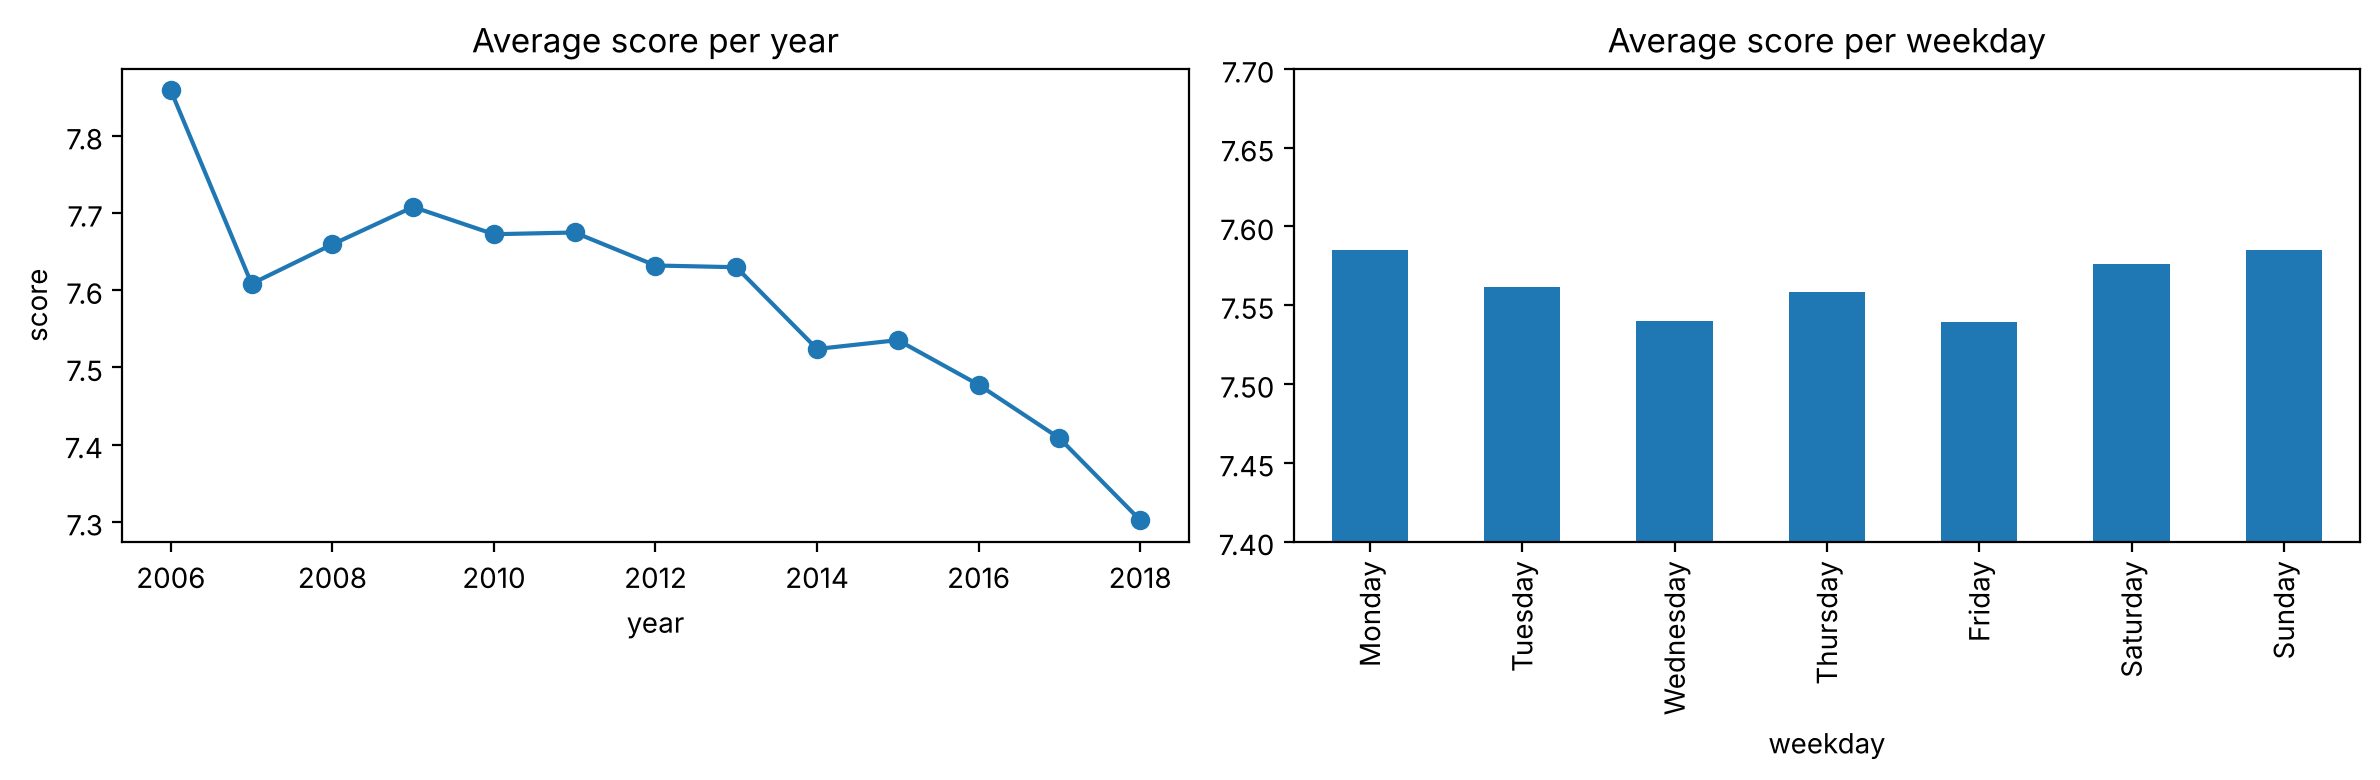

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_df.groupby("year")["score"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Average score per year")
axes[0].set_ylabel("score")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ratings_df.groupby("weekday")["score"].mean().reindex(order).plot(ax=axes[1], kind="bar")
axes[1].set_ylim(7.4, 7.7)
axes[1].set_title("Average score per weekday")
plt.tight_layout()
plt.show()

**Interpretation**

The score barely depends on weekday or season, but it does depend on the year. All tests are significant, but that's mostly because we have almost a million ratings. The effect sizes tell the real story. Weekend vs weekday has d = 0.014 (7.58 vs 7.56) and the seasons are between -0.03 and 0.02. These are way too small to matter, the plot shows the weekday bars are all around 7.55 to 7.59. The year is different: ratings from 2017 or later are 7.38 on average against 7.60 before, d = -0.125. Still a small effect, but almost 10 times bigger than weekday or season, and it's the same downward trend 02_eda found.

So for predicting the score, weekday and season are not worth using. The year is the only time context with a real effect.

The score is not the whole story though. Context can also change *which* anime people watch, even if the scores stay the same. Below we check how many ratings are on anime that came out at most one year before, and how much the 50 most rated anime change from year to year.

In [18]:
aired_year = anime_df.set_index("anime_id")["aired_from_year"]
ratings_df["anime_age"] = ratings_df["year"] - ratings_df["anime_id"].map(aired_year)

new_share = ratings_df.groupby("year")["anime_age"].apply(lambda a: (a <= 1).mean() * 100)

top50 = {y: set(g["anime_id"].value_counts().head(50).index) for y, g in ratings_df.groupby("year")}
overlap_prev = {y: len(top50[y] & top50[y - 1]) for y in range(2009, 2019)}

season_top50 = {s: set(g["anime_id"].value_counts().head(50).index) for s, g in ratings_df.groupby("season")}

context_items_df = pd.DataFrame({"% ratings on anime from the last year": new_share,
                                 "top 50 shared with previous year": pd.Series(overlap_prev)}).loc[2009:2018]
print("Top 50 shared between seasons (all years together):",
      {f"{a}-{b}": len(season_top50[a] & season_top50[b]) for a, b in [("winter", "spring"), ("spring", "summer"), ("summer", "autumn"), ("autumn", "winter")]})
context_items_df.round(1)

Top 50 shared between seasons (all years together): {'winter-spring': 22, 'spring-summer': 24, 'summer-autumn': 20, 'autumn-winter': 22}


,% ratings on anime from the last year,top 50 shared with previous year
2009,27.9,35.0
2010,30.4,26.0
2011,38.1,21.0
2012,39.0,18.0
2013,42.2,18.0
2014,45.1,10.0
2015,46.4,7.0
2016,45.8,13.0
2017,45.3,9.0
2018,42.1,11.0


**Interpretation**

Time changes *what* people watch much more than how they score it. Around 45% of all ratings since 2014 are on anime that came out at most one year before. And the most rated anime change fast: in recent years only 7 to 13 of the 50 most rated anime of a year were also in the top 50 of the year before. Back in 2009 it was 35. So people mostly watch whatever is new at that moment, and that "new" changes every year.

Seasons also look different (only 20 to 24 of the top 50 shared), but that is mostly the same thing: every season new anime start airing. Our data mixes all years in each season, so season alone doesn't add much on top of the year.

This decides the approach for the rest of the part: the useful context is "what is popular right now", not the weekday or the season.

## The context we evaluate on

The homepage is shown *now*. The data ends in May 2018, so we call "now" the last 12 months of the data. The test ratings from that period are our context test set. The models are still trained on the normal `trainset` from Part 1 (rule 1), we only look at the part of the test set that falls in the context.

In [19]:
data_end = ratings_df["last_updated"].max()
context_start = data_end - pd.Timedelta(days=365)


def add_time(df):
    df = df.copy()
    df["last_updated"] = rating_time.reindex(pd.MultiIndex.from_frame(df[["user_id", "anime_id"]])).values
    return df


test_time_df = add_time(pd.DataFrame(testset, columns=["user_id", "anime_id", "score"]))
train_time_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                      columns=["user_id", "anime_id", "score"]))

in_context = test_time_df["last_updated"] >= context_start
context_testset = list(test_time_df.loc[in_context, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

# Homepage users: the 1,000 users from Part 1 that liked at least one anime in the context period
liked_in_context = {u for u, i, r in context_testset if r >= relevant_score}
context_users = [u for u in users if u in liked_in_context]

print("Context period:", context_start.date(), "to", data_end.date())
print("Test ratings in the context:", len(context_testset), "of", len(testset))
print("Users with test ratings in the context:", test_time_df.loc[in_context, "user_id"].nunique())
print("Homepage users (of the 1,000) with a liked anime in the context:", len(context_users))

Context period: 2017-05-22 to 2018-05-22
Test ratings in the context: 20570 of 195413
Users with test ratings in the context: 2001
Homepage users (of the 1,000) with a liked anime in the context: 337


Only about 1 in 10 test ratings is from the last year. For the homepage metric we use the users from the 1,000 in Part 1 that have at least one liked anime in that period. Users with nothing in the period would get 0 hits with every model, which would just hide the differences.

## Pre-filtering

Pre-filtering means we filter the training data to the context first, and then train a normal model on it. Here: an SVD trained only on recent ratings. If a user or anime is not in the recent data, we fall back to the SVD trained on everything, otherwise long time users who were not active lately would get nothing.

We try two windows, a short one (last year) and a longer one (last 3 years). Using all years is just the normal SVD.

In [20]:
class MyPreFilterSVD(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.global_svd = SVD(random_state=my_seed)
        self.global_svd.fit(trainset)

        # Keep only the training ratings from the context window
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        recent_df = train_df[train_df["last_updated"] >= self.start]
        self.recent_trainset = Dataset.load_from_df(recent_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
        self.recent_svd = SVD(random_state=my_seed)
        self.recent_svd.fit(self.recent_trainset)
        self.recent_users = set(recent_df["user_id"])
        self.recent_items = set(recent_df["anime_id"])
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            return self.global_svd.estimate(u, i)
        raw_u, raw_i = self.trainset.to_raw_uid(u), self.trainset.to_raw_iid(i)
        if raw_u in self.recent_users and raw_i in self.recent_items:
            return self.recent_svd.predict(raw_u, raw_i).est
        # Fall back to the model trained on all the data
        return self.global_svd.estimate(u, i)

## Post-filtering

Post-filtering does it the other way around. We train the normal SVD on everything and change the ranking afterwards using the context. The tests above showed that the context changes *what* people watch more than the score, so we push up anime that a lot of people rated in the context period:

predicted score with context = SVD score + weight × context popularity

Context popularity is log(1 + number of ratings of the anime in the last year), scaled from 0 to 1. A weight of 0 is the normal SVD.

In [21]:
class MyPostFilterSVD(AlgoBase):
    def __init__(self, start, weight):
        AlgoBase.__init__(self)
        self.start = start
        self.weight = weight

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.svd = SVD(random_state=my_seed)
        self.svd.fit(trainset)

        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        popularity = np.log1p(counts) / np.log1p(counts.max())
        self.context_popularity = {trainset.to_inner_iid(a): p for a, p in popularity.items()}
        return self

    def estimate(self, u, i):
        return self.svd.estimate(u, i) + self.weight * self.context_popularity.get(i, 0)

### Choosing the weight

The weight is chosen on a validation split taken from the training data (same split as in Part 3), never on the test set. We try very small, middle and very large values, and judge them by the homepage hits on the validation ratings from the context period.

In [22]:
tune_data = Dataset.load_from_df(train_time_df[["user_id", "anime_id", "score"]], reader)
tune_trainset, tune_valset = train_test_split(tune_data, test_size=0.125, random_state=my_seed)

val_time_df = add_time(pd.DataFrame(tune_valset, columns=["user_id", "anime_id", "score"]))
context_valset = list(val_time_df.loc[val_time_df["last_updated"] >= context_start, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
val_liked = {u for u, i, r in context_valset if r >= relevant_score}
val_users = [u for u in eval_users(tune_trainset, n=1000) if u in val_liked]
print("Validation users with a liked anime in the context:", len(val_users))

tuning_rows = []
for weight in [0, 0.5, 1, 3, 10]:
    algo = MyPostFilterSVD(context_start, weight)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row = {"weight": weight}
    row.update(homepage_hits(top_n, context_valset))
    row["RMSE"] = accuracy_metrics(algo.test(context_valset))["RMSE"]
    tuning_rows.append(row)

weight_tuning_df = pd.DataFrame(tuning_rows).set_index("weight")
best_weight = weight_tuning_df["hits out of 10"].idxmax()
print("Best weight:", best_weight)
weight_tuning_df.round(3)

Validation users with a liked anime in the context: 274


Best weight: 1.0


,hits out of 10,users with at least 1 hit %,RMSE
weight,,,
0.0,0.124,10.584,1.251
0.5,0.157,13.139,1.289
1.0,0.208,18.248,1.388
3.0,0.088,7.299,2.008
10.0,0.015,1.460,2.921


**Interpretation**

A weight of 1 is the best on validation: 0.208 hits per 10 against 0.124 for the plain SVD (weight 0). Too much weight is bad. At 3 the hits drop to 0.088 and at 10 to 0.015, because then the list is basically just "most watched last year" and the user's own taste is ignored. The RMSE goes up with every weight, which makes sense since we add something to the predicted score on purpose. We care about the ranking on the homepage here, not the exact score.

## Results on the context test set

Same metrics as the other parts (rules 3 and 4), but on the test ratings from the last year. Random (the current homepage) and Bayesian popular (the baseline from Part 2) are included to compare. The Bayesian popular class is copied from Part 2 so this draft runs on its own, it can be removed when the parts are put together.

In [23]:
class MyBayesianPopularAlgorithm(AlgoBase):
    # Copied from Part 2
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return self.bayesian_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        self.C = per_item["count"].mean()
        bayesian = (self.C * self.trainset.global_mean + per_item["sum"]) / (self.C + per_item["count"])
        self.bayesian_rating_per_item = bayesian.to_dict()
        return self


part6_models = {
    "Random": MyRandomAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "SVD (no context)": SVD(random_state=my_seed),
    "Pre-filter SVD, 1 year": MyPreFilterSVD(context_start),
    "Pre-filter SVD, 3 years": MyPreFilterSVD(data_end - pd.Timedelta(days=3 * 365)),
    f"Post-filter SVD, weight {best_weight}": MyPostFilterSVD(context_start, best_weight),
}

part6_results = defaultdict(dict)
part6_top_n = {}
for name, algo in part6_models.items():
    algo.fit(trainset)
    predictions = algo.test(context_testset)
    part6_results[name].update(accuracy_metrics(predictions))
    part6_results[name].update(test_ranking_metrics(predictions))
    part6_results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, context_users, solve_ties=(name != "Random"))
    part6_top_n[name] = top_n
    part6_results[name].update(homepage_hits(top_n, context_testset))

results_part6_df = pd.DataFrame(part6_results).T
results_part6_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (20+ test items),hits out of 10,users with at least 1 hit %
Random,2.392,1.880,0.925,0.696,0.668,2001.0,0.810,0.021,1.780
Bayesian popular,1.652,1.221,0.965,0.846,0.804,2001.0,0.909,0.297,22.255
SVD (no context),1.229,0.910,0.969,0.857,0.813,2001.0,0.923,0.234,18.398
"Pre-filter SVD, 1 year",1.266,0.947,0.965,0.846,0.804,2001.0,0.911,0.231,18.398
"Pre-filter SVD, 3 years",1.235,0.916,0.968,0.858,0.814,2001.0,0.917,0.231,18.398
"Post-filter SVD, weight 1.0",1.377,1.031,0.969,0.861,0.817,2001.0,0.924,0.380,27.893


**Interpretation**

Post-filtering is the clear winner for users visiting now. It finds 0.380 liked anime per 10 shown, against 0.234 for the SVD without context. That's about 62% more. 27.9% of users get at least one hit, against 18.4%. It also beats Bayesian popular (0.297), which the plain SVD does not. Random gets 0.021, so the post-filter shows about 18 times more liked anime than the current homepage.

**Pre-filtering does not help.** Training only on the last year gives 0.231 hits and a worse RMSE (1.266 against 1.229). Using 3 years is almost the same as the normal SVD. Our guess is that cutting the data throws away too much: the last year only has about 81,000 training ratings, around a tenth of everything, so the model learns the users' taste worse. The post-filter keeps all the data to learn the taste and only uses the context to change the order at the end.

The ranking metrics on the test items (NDCG, MAP, MAR) are almost the same for all the SVD models. Like in Part 1, these only rank each user's own test ratings, so they don't show the difference. The homepage metric does.

The RMSE of the post-filter is worse (1.377), which is expected because we add the context boost to the score. It's a ranking model now, not a score predictor.

### Coverage, personalization and diversity

Rule 5: these use `full_trainset` and the 1,000 users from Part 1. We only run them for the SVD without context and the post-filter, since the question is what the context does to the lists.

In [24]:
part6_beyond = {}
for name in ["SVD (no context)", f"Post-filter SVD, weight {best_weight}"]:
    algo = part6_models[name]
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
    part6_beyond[name] = beyond_accuracy_metrics(top_n, full_trainset)
    # how new are the anime we show? (year the anime started airing)
    shown = [i for items in top_n.values() for i in items]
    part6_beyond[name]["median aired year of shown anime"] = aired_year.reindex(shown).median()

pd.DataFrame(part6_beyond).T.round(3)

,coverage %,personalization,intra-list similarity,median aired year of shown anime
SVD (no context),13.27,0.911,0.268,2012.0
"Post-filter SVD, weight 1.0",9.61,0.854,0.246,2017.0


**Interpretation**

Trade-off: more recent and a little more genre diversity, but lower coverage. Post-filter: median start year 2017 instead of 2012, a little more genre diversity (similarity within list 0.246 instead of 0.268), but coverage goes down (9.6% instead of 13.3%) and personalization too (0.854 instead of 0.911), because more users get the same recent anime. Small step towards the popular list. Most of the list (weight 1) is still personalized, but it's something to keep an eye on, since showing less of the older anime that the platform buys is probably not good.

## CVTT

The random split lets the models learn from the future (see 1.3), which is an issue for a part about time. We cross-validate through time (CVTT) with the folds from Part 1: train on the past, test on the next period. In each fold "now" is the last 12 months of the training fold. For speed we use 300 random users per fold for the homepage metric.

In [25]:
cvtt_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    fold_now = train_fold["last_updated"].max() - pd.Timedelta(days=365)

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in {"SVD (no context)": SVD(random_state=my_seed),
                       "Pre-filter SVD, 1 year": MyPreFilterSVD(fold_now),
                       f"Post-filter SVD, weight {best_weight}": MyPostFilterSVD(fold_now, best_weight)}.items():
        algo.fit(fold_trainset)
        predictions = algo.test(fold_testset)
        row = {"fold": fold, "model": name, "RMSE": accuracy_metrics(predictions)["RMSE"]}
        row.update(homepage_hits(top_n_unseen(algo, fold_trainset, fold_users, solve_ties=True), fold_testset))
        cvtt_rows.append(row)

cvtt_df = pd.DataFrame(cvtt_rows)
cvtt_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,"Post-filter SVD, weight 1.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,
1,0.980,0.867,0.817
2,0.953,0.727,0.760
3,0.840,0.693,0.687
4,0.740,0.567,0.563
5,1.230,0.917,0.963


In [26]:
cvtt_df.pivot(index="fold", columns="model", values="RMSE").round(3)

model,"Post-filter SVD, weight 1.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,
1,1.663,1.541,1.541
2,1.611,1.497,1.494
3,1.625,1.526,1.518
4,1.591,1.484,1.475
5,1.608,1.498,1.494


**Interpretation**

CVTT confirms the result. In all 5 folds the post-filter gets more homepage hits than the SVD without context, 0.74 to 1.23 against 0.56 to 0.96 per 10 (about 20 to 30% more). The pre-filter is about the same as the normal SVD again. Higher hits than the random split because here the test fold has all the future ratings of a user instead of 20% of them.

More honest test for a part about time, because the models can't learn from the future. Gain a little lower than for the random split, but it's there every time. Same as before, RMSE is worse for the post-filter (about 1.6 against 1.5) for the same reason.

## Example: one user's homepage

This is the top 10 of one context user with the normal SVD and with the post-filter. A ✓ means the user rated the anime 8 or more in the test set.

In [27]:
liked_test = defaultdict(set)
for u, i, r in context_testset:
    if r >= relevant_score:
        liked_test[u].add(i)

post_name = f"Post-filter SVD, weight {best_weight}"
# Pick the user where the post-filter gains the most hits
gain = {u: len(set(part6_top_n[post_name][u]) & liked_test[u]) - len(set(part6_top_n["SVD (no context)"][u]) & liked_test[u]) for u in context_users}
example_user = max(gain, key=gain.get)

titles = anime_df.set_index("anime_id")["title"]
def show(items):
    return [titles[i] + (" ✓" if i in liked_test[example_user] else "") for i in items]

pd.DataFrame({"SVD (no context)": show(part6_top_n["SVD (no context)"][example_user]),
              "Post-filter": show(part6_top_n[post_name][example_user])}, index=range(1, 11))

,SVD (no context),Post-filter
1,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood
2,Steins;Gate 0,3-gatsu no Lion 2nd Season
3,Baccano! Specials,Steins;Gate 0
4,Uchuu Senkan Yamato 2199,Made in Abyss ✓
5,3-gatsu no Lion 2nd Season,Baccano! Specials
6,Beck,Kizumonogatari III: Reiketsu-hen
7,Ashita no Joe 2,Shigatsu wa Kimi no Uso
8,Major: World Series,NHK ni Youkoso!
9,Romeo no Aoi Sora,Beck
10,NHK ni Youkoso!,Gintama.: Shirogane no Tamashii-hen ✓


**Interpretation**

Without context we see a lot of older anime (Ashita no Joe 2, Romeo no Aoi Sora, Uchuu Senkan Yamato 2199). With the post-filter recent anime appears like Made in Abyss and the new Gintama season, and this user did like both. Fullmetal Alchemist: Brotherhood stays number 1 in both lists, so this user's taste is still there. The post-filter only moves the recent anime up.

This is the user where the post-filter gains the most, so it's a best case, but it illustrates very well what the context does.

## Conclusion of Part 6

**Conclusion**

- Weekday and season don't seem to change the score much (d below 0.03), so we don't use them. Year has more of an impact, and especially time changes what anime people watch: almost half the ratings are on anime from the last year.
- Pre-filtering (training only on recent data) doesn't help because it wastes most of the data.
- Post-filtering (normal SVD + boost for anime that are popular right now, weight 1) gives about 62% more liked anime on the homepage than the same SVD without context, and also beats Bayesian popular. CVTT confirms it in all 5 folds.
- Lower coverage (13.3% to 9.6%) and a little less personalization. The lists are more recent and slightly more diverse in genre.

**Business-wise**, a user who opens the app today has 0.38 anime they like in the top 10 instead of 0.23, and 28% of them find at least one instead of 18%. Compared with the random homepage it's about 18 times more. The model doesn't need any new data, only the dates we already have.

**Limitations:** `last_updated` is the last edit, not the watch date, the "now" period is only about 1 in 10 test ratings, and the weight was tuned on one validation split. It should be tested online before using it, for example in the A/B test from Part 8.

**For Part 5 and Part 8**, the post-filter can be used on top of whatever CF model wins in Part 3, it doesn't have to be SVD. In the hybrid it would be the last step before showing the homepage.